# S9 - Observabilidad del pipeline con Grafana y estimación de costos

**Proyecto Sello - Equipo 10 BIG IMPACT - Salcca Aquino, Nilver**

**Objetivo:** instrumentar el pipeline de heladas de Juliaca (WeatherAPI → Kafka → Spark Streaming) con campos de observabilidad, medir su latencia y su lag con datos reales llegando en vivo, y estimar el costo de operarlo.

## 1. Entorno: SparkSession con el conector de Kafka

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion9-observabilidad")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-21b7ce13-a00f-4882-b07b-2d17a7a32db2;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.mod

## 2. Leer el topic y calcular los campos de observabilidad

In [2]:
from pyspark.sql.functions import col, from_json, current_timestamp, unix_millis
from pyspark.sql.types import StructType, StringType, DoubleType, LongType

esquema_evento = (
    StructType()
    .add("tipoEvento", StringType())
    .add("ciudad", StringType())
    .add("temperatura", DoubleType())
    .add("puntoRocio", DoubleType())
    .add("humedad", DoubleType())
    .add("nubosidad", DoubleType())
    .add("origen", StringType())
    .add("observadoEn", LongType())
    .add("timestamp", LongType())
)

crudo = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "heladas-eventos")
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "false")
    .load()
)

eventos = (
    crudo.select(
        col("topic"), col("partition"), col("offset"),
        col("timestamp").alias("kafkaTimestamp"),
        col("value").cast("string").alias("json_str"),
    )
    .select(
        "topic", "partition", "offset", "kafkaTimestamp",
        from_json(col("json_str"), esquema_evento).alias("e"),
    )
    .select("topic", "partition", "offset", "kafkaTimestamp", "e.*")
)

observables = (
    eventos
    .withColumn(
        "isValid",
        col("tipoEvento").isNotNull()
        & col("ciudad").isNotNull()
        & col("temperatura").isNotNull()
        & col("timestamp").isNotNull(),
    )
    .withColumn("processedAt", unix_millis(current_timestamp()))
    .withColumn("latencyMs", col("processedAt") - col("timestamp"))
)
observables.printSchema()

root
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- kafkaTimestamp: timestamp (nullable = true)
 |-- tipoEvento: string (nullable = true)
 |-- ciudad: string (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: double (nullable = true)
 |-- nubosidad: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- observadoEn: long (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- isValid: boolean (nullable = false)
 |-- processedAt: long (nullable = false)
 |-- latencyMs: long (nullable = true)



## 3. Ver los eventos en consola, con sus campos de observabilidad

In [3]:
consulta = (
    observables.writeStream
    .outputMode("append")
    .format("console")
    .option("truncate", "false")
    .trigger(processingTime="5 seconds")
    .start()
)

-------------------------------------------
Batch: 0
-------------------------------------------
+-----+---------+------+--------------+----------+------+-----------+----------+-------+---------+------+-----------+---------+-------+-----------+---------+
|topic|partition|offset|kafkaTimestamp|tipoEvento|ciudad|temperatura|puntoRocio|humedad|nubosidad|origen|observadoEn|timestamp|isValid|processedAt|latencyMs|
+-----+---------+------+--------------+----------+------+-----------+----------+-------+---------+------+-----------+---------+-------+-----------+---------+
+-----+---------+------+--------------+----------+------+-----------+----------+-------+---------+------+-----------+---------+-------+-----------+---------+



-------------------------------------------
Batch: 1
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1097  |2026-11-20 05:04:16.07 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151056070|true   |1795151060008|3938     |
|heladas-eventos|1        |1098  |2026-11-20 05:04:19.496|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi

-------------------------------------------
Batch: 2
-------------------------------------------
+---------------+---------+------+----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp        |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1099  |2026-11-20 05:04:22.91|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151062910|true   |1795151065008|2098     |
+---------------+---------+------+----------------------+-------------+-------+-----------+----------+-------+---------+----------+----

-------------------------------------------
Batch: 3
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1100  |2026-11-20 05:04:26.241|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151066241|true   |1795151070009|3768     |
|heladas-eventos|1        |1101  |2026-11-20 05:04:29.621|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi

-------------------------------------------
Batch: 4
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1102  |2026-11-20 05:04:33.014|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151073013|true   |1795151075009|1996     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------

-------------------------------------------
Batch: 6
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1105  |2026-11-20 05:04:43.344|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151083344|true   |1795151085012|1668     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------

-------------------------------------------
Batch: 8
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1107  |2026-11-20 05:04:50.307|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151090307|true   |1795151095010|4703     |
|heladas-eventos|1        |1108  |2026-11-20 05:04:53.709|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi

-------------------------------------------
Batch: 11
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1112  |2026-11-20 05:05:07.409|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151107409|true   |1795151110009|2600     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 12
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1113  |2026-11-20 05:05:10.787|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151110787|true   |1795151115007|4220     |
|heladas-eventos|1        |1114  |2026-11-20 05:05:14.095|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

## 4. Throughput y lag con lastProgress

-------------------------------------------
Batch: 18
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1122  |2026-11-20 05:05:41.816|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151141816|true   |1795151145008|3192     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

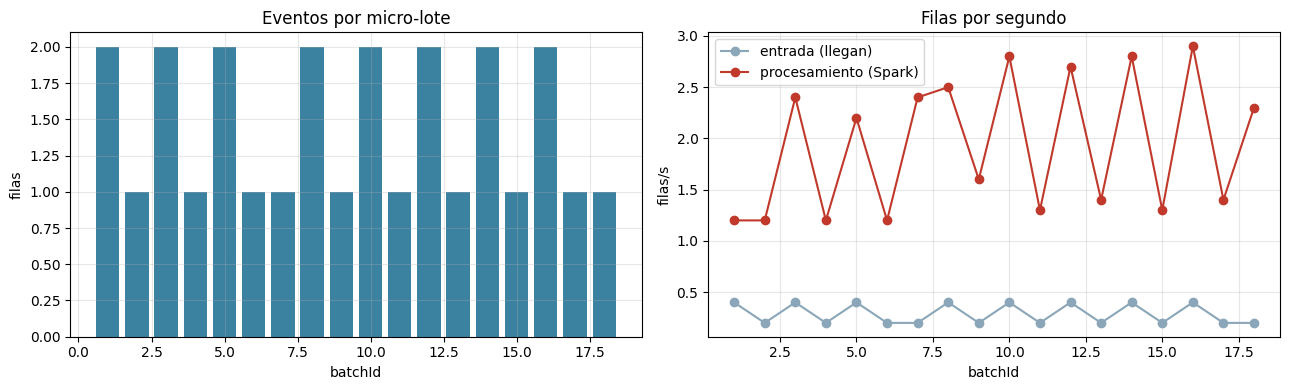

-------------------------------------------
Batch: 19
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1123  |2026-11-20 05:05:45.296|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151145296|true   |1795151150010|4714     |
|heladas-eventos|1        |1124  |2026-11-20 05:05:48.777|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 20
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1125  |2026-11-20 05:05:52.157|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151152157|true   |1795151155006|2849     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 21
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1126  |2026-11-20 05:05:55.741|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151155741|true   |1795151160016|4275     |
|heladas-eventos|1        |1127  |2026-11-20 05:05:59.123|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 25
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1132  |2026-11-20 05:06:16.557|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151176557|true   |1795151180012|3455     |
|heladas-eventos|1        |1133  |2026-11-20 05:06:19.91 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

In [4]:
import json
import pandas as pd
import matplotlib.pyplot as plt

progreso = consulta.lastProgress

if progreso is None:
    print("Todavía no hay micro-lote procesado. Espera unos segundos y corre esta celda de nuevo.")
else:
    fuente = progreso["sources"][0]
    metricas = fuente.get("metrics", {})
    estado = "idle" if progreso["numInputRows"] == 0 else "processed"

    log = {
        "service": "spark-streaming",
        "component": "observabilidad",
        "topic": "heladas-eventos",
        "batchId": progreso["batchId"],
        "numInputRows": progreso["numInputRows"],
        "inputRowsPerSecond": progreso["inputRowsPerSecond"],
        "processedRowsPerSecond": progreso["processedRowsPerSecond"],
        "avgOffsetsBehindLatest": metricas.get("avgOffsetsBehindLatest"),
        "maxOffsetsBehindLatest": metricas.get("maxOffsetsBehindLatest"),
        "status": estado,
    }
    print(json.dumps(log, indent=2))

# Gráfico: filas por tanda y velocidades de entrada y de procesamiento
hist = pd.DataFrame(consulta.recentProgress)
hist = hist[hist["numInputRows"] > 0]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].bar(hist["batchId"], hist["numInputRows"], color="#3b82a0")
ejes[0].set_title("Eventos por micro-lote")
ejes[0].set_xlabel("batchId")
ejes[0].set_ylabel("filas")

ejes[1].plot(hist["batchId"], hist["inputRowsPerSecond"], marker="o", label="entrada (llegan)", color="#8aa6b8")
ejes[1].plot(hist["batchId"], hist["processedRowsPerSecond"], marker="o", label="procesamiento (Spark)", color="#c0392b")
ejes[1].set_title("Filas por segundo")
ejes[1].set_xlabel("batchId")
ejes[1].set_ylabel("filas/s")
ejes[1].legend()

for e in ejes:
    e.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.1 Leer lo que se guardó

In [7]:
guardado = spark.read.parquet(ARTIFACTS)
total = guardado.count()
print("filas guardadas:", total)
guardado.select("ciudad", "temperatura", "latencyMs", "isValid").show(10, truncate=False)


-------------------------------------------
Batch: 47
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1164  |2026-11-20 05:08:05.916|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151285916|true   |1795151290007|4091     |
|heladas-eventos|1        |1165  |2026-11-20 05:08:09.207|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 48
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1166  |2026-11-20 05:08:12.755|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151292755|true   |1795151295009|2254     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 49
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1167  |2026-11-20 05:08:16.235|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151296235|true   |1795151300007|3772     |
|heladas-eventos|1        |1168  |2026-11-20 05:08:19.617|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 50
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1169  |2026-11-20 05:08:22.993|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151302993|true   |1795151305007|2014     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 52
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1172  |2026-11-20 05:08:33.135|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151313135|true   |1795151315004|1869     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 53
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1173  |2026-11-20 05:08:36.822|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151316822|true   |1795151320006|3184     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 55
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1176  |2026-11-20 05:08:47.274|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151327274|true   |1795151330006|2732     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 56
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1177  |2026-11-20 05:08:50.644|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151330643|true   |1795151335005|4362     |
|heladas-eventos|1        |1178  |2026-11-20 05:08:53.95 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

In [6]:
ARTIFACTS = "./artifacts/heladas_eventos_observabilidad"
CHECKPOINT_PARQUET = "./artifacts/chk_observabilidad"

consulta2 = (
    observables.writeStream
    .outputMode("append")
    .format("parquet")
    .option("path", ARTIFACTS)
    .option("checkpointLocation", CHECKPOINT_PARQUET)
    .trigger(processingTime="5 seconds")
    .start()
)
print("consulta2 activa:", consulta2.isActive)

consulta2 activa: True
-------------------------------------------
Batch: 34
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1145  |2026-11-20 05:07:01.074|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151221074|true   |1795151225009|3935     |
|heladas-eventos|1        |1146  |2026-11-20 05:07:04.454|clima.lectura|Juliaca|8.1        |5.0       |80.0

-------------------------------------------
Batch: 35
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1147  |2026-11-20 05:07:07.831|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151227831|true   |1795151230008|2177     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 37
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1150  |2026-11-20 05:07:17.969|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151237968|true   |1795151240006|2038     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 39
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1152  |2026-11-20 05:07:25.21 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151245210|true   |1795151250009|4799     |
|heladas-eventos|1        |1153  |2026-11-20 05:07:28.631|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 41
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1155  |2026-11-20 05:07:35.377|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151255377|true   |1795151260007|4630     |
|heladas-eventos|1        |1156  |2026-11-20 05:07:38.688|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 43
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1158  |2026-11-20 05:07:45.413|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151265413|true   |1795151270006|4593     |
|heladas-eventos|1        |1159  |2026-11-20 05:07:48.79 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 44
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1160  |2026-11-20 05:07:52.172|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151272171|true   |1795151275009|2838     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

-------------------------------------------
Batch: 45
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1161  |2026-11-20 05:07:55.66 |clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151275660|true   |1795151280008|4348     |
|heladas-eventos|1        |1162  |2026-11-20 05:07:59.184|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherap

-------------------------------------------
Batch: 46
-------------------------------------------
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|topic          |partition|offset|kafkaTimestamp         |tipoEvento   |ciudad |temperatura|puntoRocio|humedad|nubosidad|origen    |observadoEn  |timestamp    |isValid|processedAt  |latencyMs|
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+----------+-------------+-------------+-------+-------------+---------+
|heladas-eventos|1        |1163  |2026-11-20 05:08:02.495|clima.lectura|Juliaca|8.1        |5.0       |80.0   |68.0     |weatherapi|1795150800000|1795151282495|true   |1795151285010|2515     |
+---------------+---------+------+-----------------------+-------------+-------+-----------+----------+-------+---------+---------

In [8]:
consulta.stop()
consulta2.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


## 6. Latencia agregada por ventana de tiempo

+-------------------+-------------------+----------+------------------+------------+------------+
|inicioVentana      |finVentana         |numEventos|avgLatencyMs      |minLatencyMs|maxLatencyMs|
+-------------------+-------------------+----------+------------------+------------+------------+
|2026-11-20 05:07:00|2026-11-20 05:08:00|16        |2719.6875         |401         |4799        |
|2026-11-20 05:08:00|2026-11-20 05:09:00|17        |25953.70588235294 |252         |402380      |
|2026-11-20 05:09:00|2026-11-20 05:10:00|18        |369615.44444444444|340426      |398945      |
|2026-11-20 05:10:00|2026-11-20 05:11:00|17        |309546.8823529412 |282208      |336992      |
|2026-11-20 05:11:00|2026-11-20 05:12:00|17        |250680.5294117647 |222904      |278823      |
|2026-11-20 05:12:00|2026-11-20 05:13:00|18        |190160.05555555556|160855      |219525      |
|2026-11-20 05:13:00|2026-11-20 05:14:00|17        |129832.29411764706|102794      |157272      |
|2026-11-20 05:14:00

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


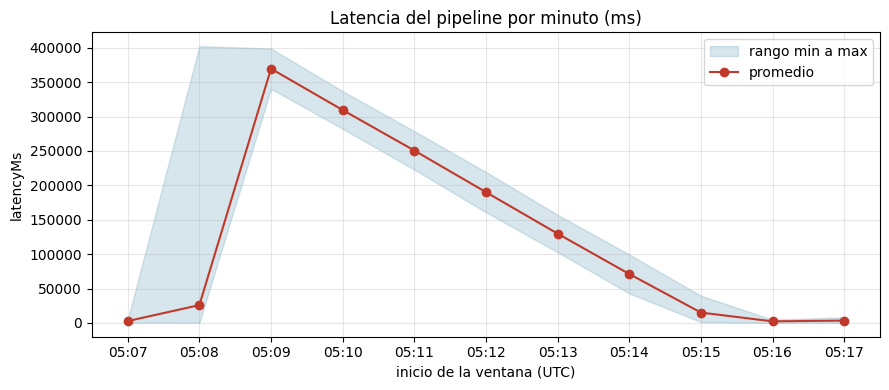

In [16]:
from pyspark.sql.functions import window, avg, min as spark_min, max as spark_max, count
import matplotlib.pyplot as plt

guardado = spark.read.parquet(ARTIFACTS)

latencia_por_minuto = (
    guardado.groupBy(window(col("kafkaTimestamp"), "1 minute"))
    .agg(
        count("*").alias("numEventos"),
        avg("latencyMs").alias("avgLatencyMs"),
        spark_min("latencyMs").alias("minLatencyMs"),
        spark_max("latencyMs").alias("maxLatencyMs"),
    )
    .select(
        col("window.start").alias("inicioVentana"),
        col("window.end").alias("finVentana"),
        "numEventos", "avgLatencyMs", "minLatencyMs", "maxLatencyMs",
    )
    .orderBy("inicioVentana")
)
latencia_por_minuto.show(20, truncate=False)

# Gráfico: latencia mínima, promedio y máxima por minuto
pdf_lat = latencia_por_minuto.toPandas()
etiquetas = pdf_lat["inicioVentana"].dt.strftime("%H:%M")

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(etiquetas, pdf_lat["minLatencyMs"], pdf_lat["maxLatencyMs"], alpha=0.2, color="#3b82a0", label="rango min a max")
ax.plot(etiquetas, pdf_lat["avgLatencyMs"], marker="o", color="#c0392b", label="promedio")
ax.set_title("Latencia del pipeline por minuto (ms)")
ax.set_xlabel("inicio de la ventana (UTC)")
ax.set_ylabel("latencyMs")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Umbrales de alerta a partir de los datos medidos

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


eventos analizados: 181
promedio global: 132085 ms
mediana (p50):   92663 ms
p95:             371095 ms
p99:             396243 ms
máximo:          402380 ms
promedio por minuto (mín/máx entre minutos): 2314 / 369615 ms


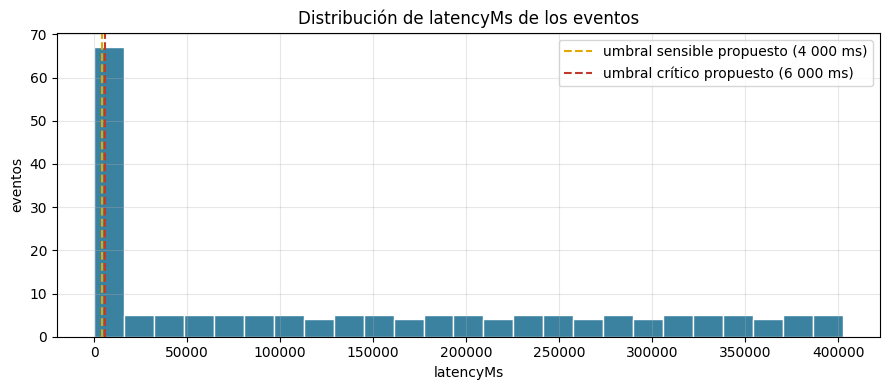

In [17]:
import numpy as np

pdf_eventos = spark.read.parquet(ARTIFACTS).select("latencyMs", "kafkaTimestamp").toPandas()
lat = pdf_eventos["latencyMs"]

print("eventos analizados:", len(lat))
print(f"promedio global: {lat.mean():.0f} ms")
print(f"mediana (p50):   {lat.quantile(0.50):.0f} ms")
print(f"p95:             {lat.quantile(0.95):.0f} ms")
print(f"p99:             {lat.quantile(0.99):.0f} ms")
print(f"máximo:          {lat.max():.0f} ms")
print(f"promedio por minuto (mín/máx entre minutos): "
      f"{pdf_lat['avgLatencyMs'].min():.0f} / {pdf_lat['avgLatencyMs'].max():.0f} ms")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lat, bins=25, color="#3b82a0", edgecolor="white")
ax.axvline(4000, color="#e0a800", linestyle="--", label="umbral sensible propuesto (4 000 ms)")
ax.axvline(6000, color="#c0392b", linestyle="--", label="umbral crítico propuesto (6 000 ms)")
ax.set_title("Distribución de latencyMs de los eventos")
ax.set_xlabel("latencyMs")
ax.set_ylabel("eventos")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Alertas propuestas y umbrales

| Situación | Regla propuesta | Dónde se evalúa | Justificación con datos medidos |
|---|---|---|---|
| Kafka no visible | `kafka_brokers < 1` | Prometheus / Grafana | Valor sano medido: `1` (consulta de Prometheus, 3.2). |
| Exporter caído | `up{job="kafka-exporter"} == 0` | Prometheus / Grafana | Valor sano medido: `1`, target en `UP`. |
| Lag alto sostenido | `kafka_consumergroup_lag > 100` durante 2 min | Prometheus / Grafana | Lag sano medido: 0 a 2. El productor genera unos 17 a 20 eventos por minuto, así que 100 equivale a unos 5 minutos de atraso. |
| Latencia sensible | `avgLatencyMs > 4000` (por minuto) | Spark / Parquet | Promedio sano medido: 2 573 ms; el mayor promedio por minuto fue 2 720 ms. |
| Latencia crítica | `avgLatencyMs > 6000` (por minuto) | Spark / Parquet | Supera el trigger de 5 s y el máximo individual medido (4 892 ms, p99 de 4 863 ms). |

**Nota:** los umbrales de la guía del docente (100 ms y 1000 ms) no se usaron: con 3 s de intervalo del productor y un trigger de 5 s, la latencia sana ya es de ~2 500 ms y esas alertas dispararían siempre.

In [13]:
print("consultas activas:", len(spark.streams.active))
for q in spark.streams.active:
    print(q.id, "|", q.isActive)

consultas activas: 0


### 5.2 Reanudar la persistencia desde el checkpoint

In [15]:
consulta2 = (
    observables.writeStream
    .outputMode("append")
    .format("parquet")
    .option("path", ARTIFACTS)
    .option("checkpointLocation", CHECKPOINT_PARQUET)
    .trigger(processingTime="5 seconds")
    .start()
)
print("consulta2 activa:", consulta2.isActive)

consulta2 activa: True


## 7.1 Separar el régimen normal del atraso

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


eventos totales: 197
en régimen normal (< 10 s): 82
del atraso (>= 10 s): 115

RÉGIMEN NORMAL -> promedio: 2642 ms | p50: 2517 | p95: 4889 | máximo: 9819

      inicioVentana  numEventos  avgLatencyMs  maxLatencyMs  estado
2026-11-20 05:07:00          16   2719.687500          4799  normal
2026-11-20 05:08:00          17  25953.705882        402380 CRÍTICA
2026-11-20 05:09:00          18 369615.444444        398945 CRÍTICA
2026-11-20 05:10:00          17 309546.882353        336992 CRÍTICA
2026-11-20 05:11:00          17 250680.529412        278823 CRÍTICA
2026-11-20 05:12:00          18 190160.055556        219525 CRÍTICA
2026-11-20 05:13:00          17 129832.294118        157272 CRÍTICA
2026-11-20 05:14:00          18  71191.000000         99504 CRÍTICA
2026-11-20 05:15:00          18  15094.166667         39606 CRÍTICA
2026-11-20 05:16:00          18   2314.166667          4825  normal
2026-11-20 05:17:00           5   3457.000000          8131  normal


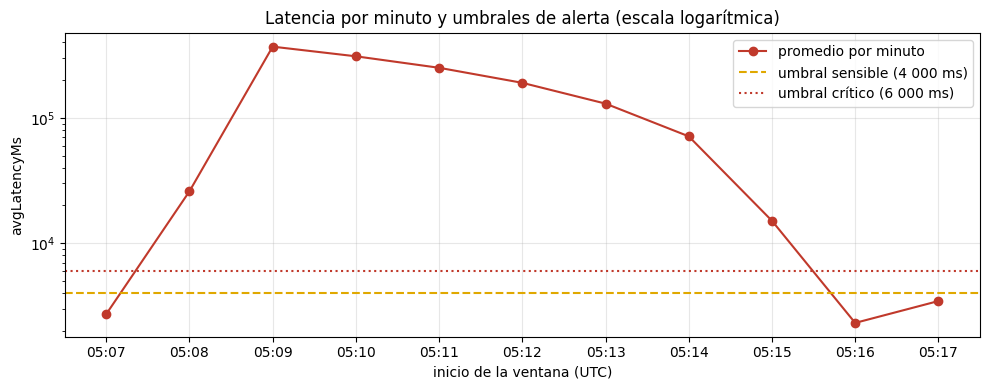

In [18]:
pdf_eventos = spark.read.parquet(ARTIFACTS).select("latencyMs", "kafkaTimestamp").toPandas()

sano = pdf_eventos[pdf_eventos["latencyMs"] < 10000]["latencyMs"]
print("eventos totales:", len(pdf_eventos))
print("en régimen normal (< 10 s):", len(sano))
print("del atraso (>= 10 s):", len(pdf_eventos) - len(sano))
print(f"\nRÉGIMEN NORMAL -> promedio: {sano.mean():.0f} ms | p50: {sano.quantile(0.5):.0f} | "
      f"p95: {sano.quantile(0.95):.0f} | máximo: {sano.max():.0f}")

def estado(valor):
    if valor > 6000:
        return "CRÍTICA"
    if valor > 4000:
        return "SENSIBLE"
    return "normal"

pdf_lat["estado"] = pdf_lat["avgLatencyMs"].apply(estado)
print()
print(pdf_lat[["inicioVentana", "numEventos", "avgLatencyMs", "maxLatencyMs", "estado"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4))
etiquetas = pdf_lat["inicioVentana"].dt.strftime("%H:%M")
ax.plot(etiquetas, pdf_lat["avgLatencyMs"], marker="o", color="#c0392b", label="promedio por minuto")
ax.axhline(4000, color="#e0a800", linestyle="--", label="umbral sensible (4 000 ms)")
ax.axhline(6000, color="#c0392b", linestyle=":", label="umbral crítico (6 000 ms)")
ax.set_yscale("log")
ax.set_title("Latencia por minuto y umbrales de alerta (escala logarítmica)")
ax.set_xlabel("inicio de la ventana (UTC)")
ax.set_ylabel("avgLatencyMs")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Estimación de costos con valores medidos

In [19]:
import os
import time

def medir_parquet():
    filas = spark.read.parquet(ARTIFACTS).count()
    archivos = [os.path.join(c, f) for c, _, fs in os.walk(ARTIFACTS) for f in fs if f.endswith(".parquet")]
    bytes_total = sum(os.path.getsize(a) for a in archivos)
    return filas, len(archivos), bytes_total

print("consulta2 activa:", consulta2.isActive)
f1, a1, b1 = medir_parquet()
print(f"medición 1 -> filas: {f1} | archivos: {a1} | tamaño: {b1/1024:.1f} KB")
time.sleep(120)
f2, a2, b2 = medir_parquet()
print(f"medición 2 -> filas: {f2} | archivos: {a2} | tamaño: {b2/1024:.1f} KB")

horas = 120 / 3600
filas_hora = (f2 - f1) / horas
mb_hora = ((b2 - b1) / 1024 / 1024) / horas
archivos_hora = (a2 - a1) / horas
gb_mes = mb_hora * 730 / 1024

# Precios de referencia de la guía (AWS us-east-1, verificar vigencia antes de entregar)
PRECIO_INSTANCIA_H = 0.0416
PRECIO_S3_GB_MES = 0.023
instancias = 3
costo_computo_mes = instancias * PRECIO_INSTANCIA_H * 730
costo_almacen_mes = gb_mes * PRECIO_S3_GB_MES

print("\n--- Plantilla de estimación de costos (valores medidos) ---")
print(f"Eventos por minuto medidos (Prometheus): 17.3  ->  {17.3/60:.2f} eventos/s")
print(f"Latencia promedio en régimen normal:     {sano.mean():.0f} ms")
print(f"Crecimiento del Parquet por hora:        {filas_hora:.0f} filas | {mb_hora:.2f} MB | {archivos_hora:.0f} archivos")
print(f"Almacenamiento proyectado:               {gb_mes:.3f} GB/mes")
print(f"Cómputo ({instancias} instancias t3.medium):    US$ {costo_computo_mes:.2f}/mes")
print(f"Almacenamiento en S3:                    US$ {costo_almacen_mes:.4f}/mes")
print(f"TOTAL estimado:                          US$ {costo_computo_mes + costo_almacen_mes:.2f}/mes")

consulta2 activa: True
medición 1 -> filas: 212 | archivos: 68 | tamaño: 314.0 KB


medición 2 -> filas: 248 | archivos: 92 | tamaño: 425.0 KB

--- Plantilla de estimación de costos (valores medidos) ---
Eventos por minuto medidos (Prometheus): 17.3  ->  0.29 eventos/s
Latencia promedio en régimen normal:     2642 ms
Crecimiento del Parquet por hora:        1080 filas | 3.25 MB | 720 archivos
Almacenamiento proyectado:               2.319 GB/mes
Cómputo (3 instancias t3.medium):    US$ 91.10/mes
Almacenamiento en S3:                    US$ 0.0533/mes
TOTAL estimado:                          US$ 91.16/mes


## 10. Estimación de costos y plan de escalado

| Variable | Valor medido en esta sesión | Supuesto para estimar costo |
|---|---|---|
| Eventos por segundo (pico) | 0.29 (17.3 por minuto, Prometheus) | Un evento cada 3 s del productor |
| Latencia promedio por minuto | 2 642 ms en régimen normal (p95 de 4 889 ms) | Trigger de 5 s |
| Crecimiento del Parquet por hora | 1 080 filas, 3.25 MB y 720 archivos | 2.3 GB al mes |
| Costo de cómputo | US$ 91.10 al mes | 3 instancias t3.medium a US$ 0.0416 por hora, 730 horas (AWS us-east-1, precio de referencia de la guía) |
| Costo de almacenamiento | US$ 0.05 al mes | S3 Standard a US$ 0.023 por GB al mes |
| **Total estimado** | **US$ 91.16 al mes** | Sin tráfico de red ni mantenimiento |

### Plan de escalado

| Umbral de decisión | Dato medido que lo justifica | Acción |
|---|---|---|
| `kafka_consumergroup_lag > 100` por más de 2 min, o latencia promedio por minuto > 6 000 ms | Lag sano: 0 a 2. En el atraso de las 00:09 la latencia llegó a 369 s y el sistema tardó unos 7 minutos en recuperarse. | Revisar primero el consumidor (Spark); si se repite, subir los recursos de la instancia de Spark. |
| `inputRowsPerSecond` mayor a 1 fila/s (la mitad de la capacidad medida) | Spark procesó 2.3 filas/s con una entrada de 0.2 filas/s: hay unas 11 veces de holgura. | Añadir más ciudades (más claves) y subir particiones y paralelismo antes de agregar máquinas. |

**Qué escalaría primero:** el consumidor de Spark, no el broker ni la escritura a Parquet. Hoy todo el tráfico va a una sola partición porque la `key` es siempre "Juliaca"; agregar particiones no ayuda mientras haya una sola clave. Escalaría al incorporar nuevas ciudades.

**Riesgo de retener el Parquet sin limpieza:** el volumen (2.3 GB al mes) cuesta centavos, pero 720 archivos pequeños por hora (unos 17 mil al día) degradan las lecturas. Haría falta una compactación periódica y una política de retención.

In [21]:
consulta2.stop()
print("consultas activas:", len(spark.streams.active))

consultas activas: 0


26/11/20 05:22:02 ERROR FileFormatWriter: Aborting job 61451e58-5290-438f-b711-15e627ea0938.
java.lang.InterruptedException
	at java.base/java.util.concurrent.locks.AbstractQueuedSynchronizer.tryAcquireSharedNanos(AbstractQueuedSynchronizer.java:1167)
	at scala.concurrent.impl.Promise$DefaultPromise.tryAwait0(Promise.scala:251)
	at scala.concurrent.impl.Promise$DefaultPromise.result(Promise.scala:271)
	at org.apache.spark.util.SparkThreadUtils$.awaitResultNoSparkExceptionConversion(SparkThreadUtils.scala:78)
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:44)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:101)
	at org.apache.spark.rpc.RpcEndpointRef.askSync(RpcEndpointRef.scala:85)
	at org.apache.spark.storage.B